In [1]:
from typing import Dict , TypedDict 
from langgraph.graph import StateGraph

In [3]:
class AgentState(TypedDict):
  name: str
  age: str
  skills: list[str]
  final: str

In [9]:
def name_node(state: AgentState) -> AgentState:
  """ Simple function that greets with the name """
  state["final"] = f"Hey {state['name']}, Welcome to the System!"
  return state 

def age_node(state: AgentState) -> AgentState:
  """ Simple function to add age in the existing state"""
  state["final"] = state["final"]+ f" Your are {state['age']} years old!."
  return state

def skills_node(state: AgentState) -> AgentState:
  """ Simple Function to add skills in the existing state """
  state["final"] = state["final"]+f"You have skills in: {state['skills']}."
  return state

In [10]:
graph = StateGraph(AgentState)
graph.add_node("name_node", name_node)
graph.add_node("age_node", age_node)
graph.add_node("skills_node", skills_node)
graph.set_entry_point("name_node")
graph.add_edge("name_node", "age_node")
graph.add_edge("age_node", "skills_node")
graph.set_finish_point("skills_node")

app = graph.compile()


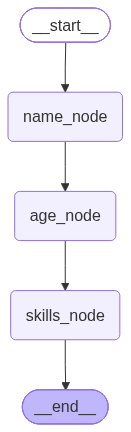

In [11]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [12]:
results = app.invoke({"name": " Bob", "age": "22", "skills":["cpp", "graning", "expert"]})
print(results)
print(results["final"])

{'name': ' Bob', 'age': '22', 'skills': ['cpp', 'graning', 'expert'], 'final': "Hey  Bob, Welcome to the System! Your are 22 years old!.You have skills in: ['cpp', 'graning', 'expert']."}
Hey  Bob, Welcome to the System! Your are 22 years old!.You have skills in: ['cpp', 'graning', 'expert'].
